In [1]:
%% MIT 18.03 Lecture 32: Linear First-Order Systems, State-Space & Companion Matrices
% Description: Simulates coupled 1st-order LTI systems u' = A*u via Control System Toolbox:
%              1) Rabbit Migration Model: A = [0.3, 0.1; 0.2, 0.4], eigenvalues 0.5 and 0.2,
%                 eigenvector rays [1; 2] and [1; -1].
%              2) Romeo & Juliet Companion Matrix: A = [0, 1; -17/16, 1/2], poles at 1/4 +/- i,
%                 tracing an outward expanding spiral from u(0) = [1; 0].
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole, tf).
%
% % MBD Concept Mapping: Formalizes continuous-time State-Space models (du/dt = A*u).
% %                      Connects 2nd-order scalar ODEs to Companion Matrices (Controllable Canonical Form),
% %                      and maps matrix eigenvectors to invariant phase-plane modal directions.


clear; clc; close all;


%% =========================================================================
%% Part 1: Jones & McGregor Rabbit System (Sections [1] & [2])
%% =========================================================================
% System: x' = 0.3x + 0.1y,  y' = 0.2x + 0.4y  -->  u' = A_rabbit * u
A_rabbit = [0.3, 0.1;
            0.2, 0.4];


% Construct autonomous State-Space object via Control System Toolbox
% Output matrix C = eye(2) to observe full state vector u = [x; y]
sys_rabbit = ss(A_rabbit, zeros(2,1), eye(2), zeros(2,1));


% Eigenvalue & Eigenvector decomposition
[V_rab, D_rab] = eig(A_rabbit);
poles_rabbit = pole(sys_rabbit);


% Normalize eigenvectors to match lecture integer forms: v1 = [1; 2], v2 = [1; -1]
v1_mode = [1; 2];  % Corresponding to r1 = 0.5 (Dominant fast growth mode)
v2_mode = [1; -1]; % Corresponding to r2 = 0.2 (Slow growth mode)


fprintf('=== MIT 18.03 Lecture 32 State-Space Diagnostics ===\n');

=== MIT 18.03 Lecture 32 State-Space Diagnostics ===

In [2]:
fprintf('1) Rabbit Population Matrix A = [0.3, 0.1; 0.2, 0.4]\n');

1) Rabbit Population Matrix A = [0.3, 0.1; 0.2, 0.4]

In [3]:
fprintf('   Characteristic Polynomial: s^2 - %.1fs + %.1f = 0\n', trace(A_rabbit), det(A_rabbit));

   Characteristic Polynomial: s^2 - 0.7s + 0.1 = 0

In [4]:
fprintf('   Eigenvalues (Poles)      : r1 = %.2f, r2 = %.2f\n', poles_rabbit(1), poles_rabbit(2));

   Eigenvalues (Poles)      : r1 = 0.20, r2 = 0.50

In [5]:
fprintf('   Mode 1 Ray (r1 = 0.5)    : [%d; %d]\n', v1_mode(1), v1_mode(2));

   Mode 1 Ray (r1 = 0.5)    : [1; 2]

In [6]:
fprintf('   Mode 2 Ray (r2 = 0.2)    : [%d; %d]\n\n', v2_mode(1), v2_mode(2));

   Mode 2 Ray (r2 = 0.2)    : [1; -1]

In [7]:


%% =========================================================================
%% Part 2: Romeo & Juliet Companion Matrix System (Sections [3] & [4])
%% =========================================================================
% ODE: x'' - (1/2)x' + (17/16)x = 0  <--->  R' = J, J' = -(17/16)R + (1/2)J
A_romeo = [0,       1;
           -17/16,  1/2];


sys_romeo = ss(A_romeo, zeros(2,1), eye(2), zeros(2,1));
poles_romeo = pole(sys_romeo);


fprintf('2) Romeo & Juliet Companion Matrix A = [0, 1; -17/16, 1/2]\n');

2) Romeo & Juliet Companion Matrix A = [0, 1; -17/16, 1/2]

In [8]:
fprintf('   Characteristic Polynomial: s^2 - 0.5s + 1.0625 = (s - 0.25)^2 + 1 = 0\n');

   Characteristic Polynomial: s^2 - 0.5s + 1.0625 = (s - 0.25)^2 + 1 = 0

In [9]:
fprintf('   Eigenvalues (Poles)      : %+.4f %+.4fi, %+.4f %+.4fi\n', ...
        real(poles_romeo(1)), imag(poles_romeo(1)), real(poles_romeo(2)), imag(poles_romeo(2)));

   Eigenvalues (Poles)      : +0.2500 +1.0000i, +0.2500 -1.0000i

In [10]:
fprintf('====================================================\n');


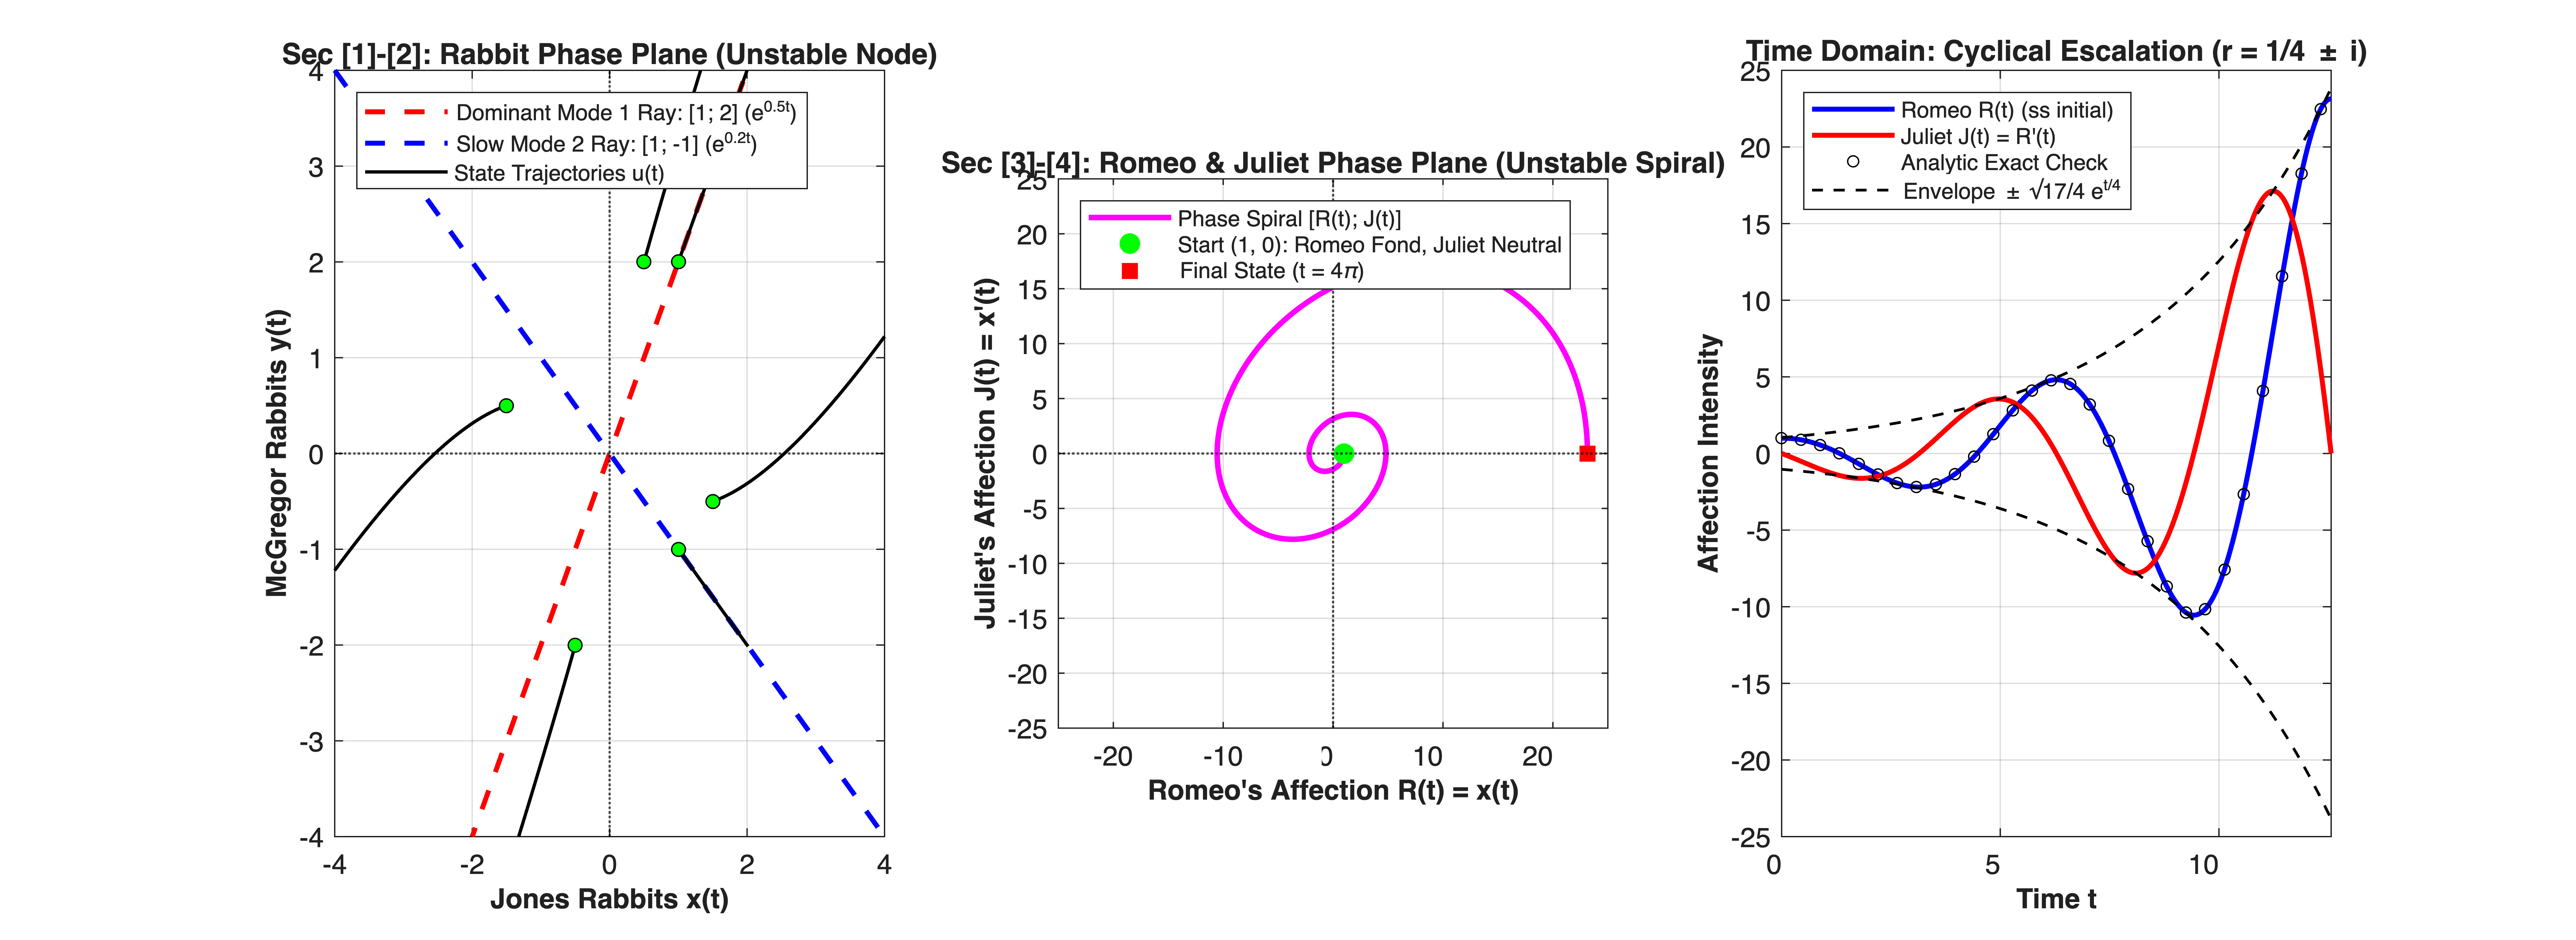

In [11]:


% Simulate Romeo & Juliet starting from u(0) = [R(0); J(0)] = [1; 0]
t_rj = linspace(0, 4 * pi, 1000);
u0_rj = [1; 0];
[u_rj_sim, ~] = initial(sys_romeo, u0_rj, t_rj);


% Analytical verification for R(t) with R(0)=1, R'(0)=J(0)=0:
% R(t) = e^{t/4} * (cos(t) - (1/4)*sin(t))
R_exact = exp(t_rj / 4) .* (cos(t_rj) - 0.25 * sin(t_rj));
J_exact = exp(t_rj / 4) .* (-17/16 * sin(t_rj));


%% =========================================================================
%% Part 3: Multi-Panel Phase Plane & Time-Domain Visualization
%% =========================================================================
figure('Color', [1 1 1], 'Position', [70, 70, 1260, 460]);


% Subplot 1: Rabbit System Phase Plane & Modal Rays
subplot(1, 3, 1);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Plot invariant eigenvector lines
s_line = linspace(-4, 4, 100);
plot(s_line * v1_mode(1), s_line * v1_mode(2), 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Dominant Mode 1 Ray: [1; 2] (e^{0.5t})');
plot(s_line * v2_mode(1), s_line * v2_mode(2), 'b--', 'LineWidth', 1.8, ...
     'DisplayName', 'Slow Mode 2 Ray: [1; -1] (e^{0.2t})');


% Simulate trajectories from mixed initial conditions via 'initial'
t_rab = linspace(0, 3.5, 300);
u0_list = [1, 2;  1, -1;  1.5, -0.5;  -1.5, 0.5;  0.5, 2.0;  -0.5, -2.0]';
for k = 1:size(u0_list, 2)
    [u_traj, ~] = initial(sys_rabbit, u0_list(:, k), t_rab);
    plot(u_traj(:, 1), u_traj(:, 2), 'k-', 'LineWidth', 1.2, 'HandleVisibility', 'off');
    plot(u0_list(1, k), u0_list(2, k), 'ko', 'MarkerFaceColor', 'g', ...
         'MarkerSize', 5, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'k-', 'LineWidth', 1.2, 'DisplayName', 'State Trajectories u(t)');


xlabel('Jones Rabbits x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('McGregor Rabbits y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [1]-[2]: Rabbit Phase Plane (Unstable Node)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
xlim([-4, 4]); ylim([-4, 4]);


% Subplot 2: Romeo & Juliet Phase Plane (Outward Expanding Spiral)
subplot(1, 3, 2);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


plot(u_rj_sim(:, 1), u_rj_sim(:, 2), 'm-', 'LineWidth', 2.0, ...
     'DisplayName', 'Phase Spiral [R(t); J(t)]');
plot(u0_rj(1), u0_rj(2), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 7, ...
     'DisplayName', 'Start (1, 0): Romeo Fond, Juliet Neutral');
plot(u_rj_sim(end, 1), u_rj_sim(end, 2), 'rs', 'MarkerFaceColor', 'r', ...
     'MarkerSize', 7, 'DisplayName', 'Final State (t = 4\pi)');


xlabel('Romeo''s Affection R(t) = x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Juliet''s Affection J(t) = x''(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [3]-[4]: Romeo & Juliet Phase Plane (Unstable Spiral)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
axis equal; xlim([-25, 25]); ylim([-25, 25]);


% Subplot 3: Romeo & Juliet Time-Domain Growing Oscillations
subplot(1, 3, 3);
hold on; grid on; box on;
plot(t_rj, u_rj_sim(:, 1), 'b-', 'LineWidth', 1.8, 'DisplayName', 'Romeo R(t) (ss initial)');
plot(t_rj, u_rj_sim(:, 2), 'r-', 'LineWidth', 1.8, 'DisplayName', 'Juliet J(t) = R''(t)');
plot(t_rj(1:35:end), R_exact(1:35:end), 'ko', 'MarkerSize', 4, 'DisplayName', 'Analytic Exact Check');


% Exponential envelope for R(t): A = sqrt(1 + 1/16) = sqrt(17)/4
A_env = sqrt(17) / 4;
plot(t_rj, A_env * exp(t_rj / 4), 'k--', 'LineWidth', 1.0, 'DisplayName', 'Envelope \pm \surd{17}/4 e^{t/4}');
plot(t_rj, -A_env * exp(t_rj / 4), 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');


xlabel('Time t', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Affection Intensity', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Domain: Cyclical Escalation (r = 1/4 \pm i)', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
xlim([0, 4 * pi]);